## Pegasus Evaluation: Evidence per Service

Section B.2 of the evaluation of the paper. The evaluation is split into `2a_base_case.ipynb` (A, B.1), `2b_evidence.ipynb` (B.2), `2c_depth_and_load.ipynb` (B.3, B.4), `2d_tails_and_percentiles.ipynb` (B.5, B.6) and `2e_iterative.ipynb` (C.1, C.2). `2a_base_case.ipynb` describes
the two data sources, the setup (A) and the metrics and methods (B.1) that every notebook uses; the parameters are
defined once in `pegasus/evaluation_setup.py`. Choose the data source with `data_source` in the first code cell.

In [1]:
# Data source of every experiment:
# - "synthetic": generated services and a simulated chain of queues (pegasus/data.py, pegasus/simulation.py)
# - "real": the measured runs of the second testbed campaign in statics/results_milos_v2 (pegasus/real_data.py)
data_source = "real"

# the parameters and helpers that every evaluation notebook shares, defined once in pegasus/evaluation_setup.py
from pegasus.evaluation_setup import *
from pegasus.figures import math_label
p_label = math_label(p_label)   # the quantile name in the math notation of the paper, e.g. $P_{95}$, for the figures and the text
globals().update(configure(data_source))
# the base case of B.1 that this notebook builds on: read from statics/evaluation_cache/ (written by the first
# notebook that needs it), or computed here if the cache is missing or stale (b1_base)
globals().update(b1_base(data_source))
print(f"{data_source} data, {len(seeds)} seeds: chain {' -> '.join(base.path)}, per seed {n_train} training configurations per service and "
      f"{len(base.measured)} held-out configurations, {arrivals}")

base case of B.1 loaded from statics/evaluation_cache/b1_real+b1+b1u-max3_884f34446e6214f4.joblib
real data, 3 seeds: chain detector -> transformer -> compressor, per seed 25 training configurations per service and 120 held-out configurations, poisson arrivals at one rate per configuration (1.58 to 65/s)


## B. Coverage and Tightness of Service Bounds

The metrics, the methods and the rule *validity before tightness* are those of B.1 (`2a_base_case.ipynb`).

### B.2 Varying Evidence per Service

**Question.** A chain is only as well known as its least known service. If the training runs of a chain are collected
one service at a time, which service should get them, and how many runs does the bound need to become valid and
tight?

- **Synthetic:** the chain of B.1 ($s_1 \to s_2 \to s_3$), with up to 200 training configurations per service.
- **Real:** the chain denoiser → object detector → face detector → compressor (`EVIDENCE_CHAIN` in
  `pegasus/evaluation_setup.py`, `b1-vision-3-single` with its runs in `b1-unthrottled/` with at most three workers per
  service, as in B.1). Of all chains of the campaign, its services are the least evenly known: with few training runs,
  the models of the object detector and the face detector are far more uncertain than those of the other two services,
  so the order in which the services get their runs matters. Which service the rule below picks first follows from the
  models, not from this choice of chain (the conclusion names it).
- **Baselines:** as in B.1 without DNN Sum (see Methods in B.1), each with the same training data as the proposed
  method. Of the proposed method, only Pegasus Node is evaluated: Pegasus SNC is evaluated in B.1 and B.3 only.

**Training data (real data).** Unlike B.1, every service is trained on its benchmark *and* on its runs in the other
chains of `b1/` (`BENCHMARK_AND_CHAINS` in `pegasus/real_data.py`); the evaluated chain and its twin in
`b1-unthrottled/` are left out, so the chain stays an unseen composition. The reason: a benchmark measures ten
configurations of its service, each at five utilizations, so beyond a few dozen runs it only adds repetitions of the
same configurations. The other chains drew the configuration of every run at random and add configurations that the
benchmark lacks. They run every service with one worker, as the benchmark does. A training run is one run with its
mean and its spread, as in B.1; with synthetic data, one training configuration with one execution time.

**Setting.** B.2 does not use the chain of B.1 that the first code cell loads and prints; it takes from that base case
only the number of training runs per service of B.1, for the calibration share of Conformal (below). For every seed,
the training runs of every service come in one random order (`evidence_data` in `pegasus/evaluation_setup.py`), and
$n$ runs of a service are the first $n$ of them, so that more runs only add to the fewer ones. Every service starts
with the first number of `evidence_levels` (in the code cell below) and moves up through these numbers, the last step
being all its runs (`service_levels` in `pegasus/evidence.py`). One *step* moves one service to its next number; after
every step the models are fitted anew, and every method is computed on the held-out runs, which are those of B.1 for
this chain and the same under every seed. A *schedule* decides which service moves (`pegasus/evidence.py`):
- *All services together:* the services in turn, in the order of the chain, so that all of them grow alike.
- *Most uncertain first:* the service whose uncertainty costs the bound of Pegasus Node the most. Let $\bar m_k(x)$ be
  the pessimistic mean execution time of service $k$ at the held-out configuration $x$ (s, see Methods in B.1),
  $m_k(x)$ its predicted mean (s), and $d_k$ the node bound of service $k$ at the violation probability
  $\varepsilon / |S|$ (s, as in Pegasus Node), computed from a mean and the variance per item. The *cost of the
  uncertainty* of service $k$ is the median over the held-out configurations of $d_k(\bar m_k(x)) - d_k(m_k(x))$: how
  much its node bound would shrink if its mean were known (infinite where only the pessimistic mean overloads the
  service). It uses the models, the held-out configurations and their arrival rates, not a single measured latency, so
  it can be computed before the chain ever runs: a rule that a user can follow (`uncertainty_cost`).
- *Least uncertain first:* the service with the smallest cost, the control.

Conformal sets aside the same share of the runs of the service with the fewest runs for calibration as in B.1, and at
least 19, the fewest that give it a finite bound; it is left out where fewer than 5 runs would remain to train its
model. The Oracle uses no training data.

**Uncertainty per service.** The model of a service is trained on the runs of that service alone, so its uncertainty
depends only on how many runs the service has, not on the runs of the other services or on the schedule. It is
therefore computed once per number of runs, on a finer grid than the steps (`uncertainty_levels` in its code cell,
then all runs of the service), with the same random order of the runs and the same held-out configurations. Besides
the predicted mean execution time $m_k(x)$ and the node bound $d_k(m_k(x))$, which show how fast the service is and how
long an item stays at it, two measures of the uncertainty, all per service and all the median over the held-out
configurations:
- the *uncertainty margin of the mean*, $\delta_k = \bar m_k(x) / m_k(x) - 1$ (no unit): how much slower than
  predicted the bound assumes the service to be; 0.1 means 10% slower. It is one-sided: the model is uncertain in both
  directions, but the bound uses only the pessimistic mean, above which the true mean lies with probability
  $1 - \gamma$, so $\delta_k$ is written with a plus, not a plus-minus. With real data the mean model is a GP on the logarithm of the run
  means, so $\bar m_k(x) = m_k(x)\, e^{z_\gamma \sigma_k(x)}$ and the margin is $e^{z_\gamma \sigma_k(x)} - 1$, where
  $\sigma_k(x)$ is the standard deviation of the predicted logarithm of the mean of a new run and $z_\gamma$ the
  standard normal quantile at the confidence level $\gamma$ (B.1). $\sigma_k(x)$ contains the scatter between runs at
  the same configuration as well as the GP's uncertainty about the mean function; more runs only remove the second
  part, so the margin is expected to level off at the run-to-run scatter instead of falling to zero;
- the *cost of the uncertainty* (s) as defined above, the quantity by which *most uncertain first* ranks the services.
  It weighs the margin by how slow and how busy the service is: the same margin costs more seconds at a slow service
  close to overload than at a fast one.

**Figures.** Every line is the median over the seeds, and the band around it reaches from the smallest to the largest
seed; the legend of every figure sits inside it where it hides the fewest points.
- *Schedules* (`b2_evidence_<data source>_schedules_tightness`): the tightness of Pegasus Node under every schedule over
  the total number of training runs of the chain, all services together (logarithmic), for every seed the median over
  the held-out configurations. Under the two schedules that look at the uncertainty, the services move in a different
  order under every seed; the horizontal position of a step is then the median over the seeds of the total number of
  runs. The horizontal line at 1× is the measured quantile; in the red area below it ("underestimated: SLO violated")
  the bound lies under the measured quantile. A filled marker means that the bound holds after that step (it reaches
  the confidence level under every seed, as defined in B.1), a hollow marker that it does not; a step has no point
  where the bound is infinite at half of the held-out configurations or more under half of the seeds or more. Look at
  how many runs each schedule needs before its markers are filled, and where its line is lowest.
- *Uncertainty per service* (`b2_evidence_<data source>_uncertainty_execution` and `_cost`, two figures side by side,
  each with its own vertical axis): one line per service over the training runs of that service (logarithmic). Left
  (*how uncertain*, s, logarithmic): the line is the predicted mean execution time $m_k$, the band reaches up to the
  pessimistic mean $m_k (1 + \text{margin})$ that the bound uses, so on the logarithmic axis the height of the band is
  the margin, the uncertainty relative to how fast the service is; every value is the median over the seeds. The
  margin with all runs is also written as a percentage at the end of every line: "$\delta$ = +3%" means that the bound
  assumes the service to be 3% slower than predicted. Right
  (*what it costs the chain*, s, logarithmic): the cost of the uncertainty of every service, the median over the seeds
  with a band from the smallest to the largest seed, against the end-to-end bound of Pegasus Node when every service
  has that many runs (a service with fewer runs holds all of them; green circles, its style in every figure, with a
  band over the seeds) and the Oracle of B.1 (purple stars, dashed, as in every figure), which uses no training data
  and is the same at every number of runs. The gap between Pegasus Node and the Oracle has two parts: the cost of the
  uncertainty of all services together, which more runs remove, and the looseness of the node bound itself together
  with the error of the predicted means, which stays. Compare the order of the services in the two figures at the
  fewest runs: a service can be the most uncertain relative to its own execution time and still cost the chain
  little, because it is fast and its seconds of uncertainty are few; the order on the right is the order in which
  *most uncertain first* feeds the services. Compare each cost with the gap between Pegasus Node and the Oracle to see
  which service makes the bound loose, and where the bound of Pegasus Node flattens, beyond which more runs no longer
  tighten it.
- *Methods* (`b2_evidence_<data source>_tightness`): the tightness of every method under *all services together* over
  the total number of training runs of the chain, read as the first figure.

The figures are saved in `figures/tsc/` as `.pdf` and `.jpg`.

In [2]:
# B.2: the chain of B.2 while the training runs of its services grow one service at a time, under every schedule (pegasus/evidence.py)
from pegasus.evidence import (ALL_TOGETHER, COLORS as SCHEDULE_COLORS, MOST_UNCERTAIN, SCHEDULES, STYLES as SCHEDULE_STYLES, incremental_training,
                              schedule_figure)
from pegasus.figures import METHOD_STYLES

METHOD_COLORS.update(SCHEDULE_COLORS)   # sweep_line draws a line by its name
METHOD_STYLES.update(SCHEDULE_STYLES)
evidence_levels = [3, 10, 50]                 # training runs (configurations) per service at which a service stops; then all of them
calibration_share = n_calibration / n_train   # share of its runs that Conformal sets aside for calibration, as in B.1


def compute():
    evidence = {}         # (schedule, seed) -> per step: (runs per service, name -> (group, latency per held-out configuration),
                          #                               name -> (training time, evaluation time) in s, the service that moves up next)
    evidence_truth = {}   # seed -> (measured quantile, lower edge of its confidence interval) per held-out configuration
    with warnings.catch_warnings():
        # with few training runs the fitted GP hyperparameters often end at their bounds, and scikit-learn warns for every model
        warnings.simplefilter("ignore", ConvergenceWarning)
        for s in seeds:
            data = evidence_data(s)
            assert_unseen(data)
            evidence_truth[s] = (data.measured, data.measured_low)
            for schedule in SCHEDULES:
                evidence[(schedule, s)] = incremental_training(data, schedule, evidence_levels, alpha, confidence, calibration_share,
                                                               model_seed=seed + s, leave_out=only_base_case + (PROPOSED_SNC,))
    return dict(evidence=evidence, evidence_truth=evidence_truth, evidence_path=data.path)


globals().update(cached("b2_evidence", data_source, compute, inputs=dict(levels=evidence_levels, calibration_share=calibration_share)))
n_steps = len(evidence[(ALL_TOGETHER, seeds[0])])
print(f"{len(SCHEDULES)} schedules of {n_steps} training states each evaluated for {len(seeds)} seeds on {' -> '.join(evidence_path)}, "
      f"{len(evidence_truth[seeds[0]][0])} held-out configurations.")

b2_evidence: results loaded from statics/evaluation_cache/b2_evidence_real+b1+b1u-max3_70049e932078bb04.joblib
3 schedules of 13 training states each evaluated for 3 seeds on denoiser -> detector -> faces -> compressor, 107 held-out configurations.


In [3]:
# B.2: the uncertainty of every service model against its own training runs, on a finer grid of runs than evidence_levels.
# A service model is trained on the runs of its service alone, so its uncertainty depends neither on the runs of the other
# services nor on the schedule: one fit per number of runs suffices for every schedule
from pegasus.bounds import martingale_closed_form_node_bounds
from pegasus.evaluation import pegasus_bound
from pegasus.evidence import service_levels, training_prefix, uncertainty_cost
from pegasus.service_gp import execution_time_belief, run_statistics_belief

uncertainty_levels = [3, 5, 10, 20, 50, 100, 200]   # training runs per service at which its model is fitted; then all of them


def compute():
    # seed -> service -> array (levels, 5), every value but the runs the median over the held-out configurations: training runs,
    # uncertainty margin of the mean, uncertainty cost (s), predicted mean execution time (s), node bound with the predicted mean (s)
    uncertainty = {}
    chain_bound = {}   # seed -> end-to-end bound of the chain with the predicted means and all runs of every service (s), the reference
                       #         against which the cost of the uncertainty of a service is read
    chain_pegasus = {}   # seed -> array (levels, 3): training runs per service (a service with fewer runs holds all of them), the
                         #         end-to-end bound of Pegasus Node with the pessimistic means and that with the predicted means (s), each the
                         #         median over the held-out configurations; per configuration, the first minus the second is the summed cost
    with warnings.catch_warnings():
        # with few training runs the fitted GP hyperparameters often end at their bounds, and scikit-learn warns for every model
        warnings.simplefilter("ignore", ConvergenceWarning)
        for s in seeds:
            data = evidence_data(s)
            steps = service_levels(data, uncertainty_levels)
            belief_of = run_statistics_belief if data.y_train_spread is not None else execution_time_belief
            x_test = model_inputs(data.x_test, data.workers_column)   # the models receive no number of workers
            rows = {service: [] for service in data.path}
            chain_rows = []
            # one fit of all services per level; a service that already holds all its runs keeps them and is not recorded again
            n_levels = max(len(n) for n in steps.values())
            for j in range(n_levels):
                n = {service: steps[service][min(j, len(steps[service]) - 1)] for service in data.path}
                part = training_prefix(data, n)
                models = fit_services(part, part.x_train, part.y_train, model_seed=seed + s, confidence=confidence, with_dnn=False)
                cost = uncertainty_cost(part, models, alpha)
                # the median belief is the predicted mean; with the variance per item of the pessimistic belief, as in uncertainty_cost
                predicted = [(belief_of(models["gp"][service], configurations_of(x_test, service), 0.5)[0], var)
                             for service, (_, var) in zip(data.path, models["beliefs"])]
                bound = martingale_closed_form_node_bounds(predicted, epsilon=alpha / len(data.path), path_workers=path_workers(data), **data.workload)
                chain_rows.append((max(n.values()), float(np.median(pegasus_bound(part, models, alpha))), float(np.median(bound.sum(axis=0)))))
                if j == n_levels - 1:   # every service holds all its runs
                    chain_bound[s] = float(np.median(bound.sum(axis=0)))   # the sum per held-out configuration, then the median
                for k, (service, (pessimistic, _)) in enumerate(zip(data.path, models["beliefs"])):
                    if j < len(steps[service]):
                        mean = predicted[k][0]
                        rows[service].append((n[service], float(np.median(pessimistic / mean - 1)), cost[service], float(np.median(mean)),
                                              float(np.median(bound[k]))))
            uncertainty[s] = {service: np.array(r) for service, r in rows.items()}
            chain_pegasus[s] = np.array(chain_rows)
    return dict(uncertainty=uncertainty, chain_bound=chain_bound, chain_pegasus=chain_pegasus)


globals().update(cached("b2_uncertainty", data_source, compute, inputs=dict(levels=uncertainty_levels)))
print(f"service models fitted at {', '.join(f'{service} {len(uncertainty[seeds[0]][service])}' for service in evidence_path)} numbers of training runs "
      f"for {len(seeds)} seeds.")

b2_uncertainty: results loaded from statics/evaluation_cache/b2_uncertainty_real+b1+b1u-max3_19df9d260a7fb012.joblib
service models fitted at denoiser 7, detector 8, faces 8, compressor 8 numbers of training runs for 3 seeds.


B.2 evidence per service, real data: denoiser → detector → faces → compressor, Pegasus Node under every schedule, 107 held-out configurations, 3 seeds
save_figure: b2_evidence_real_schedules_tightness reaches beyond the figure by {'right': np.float64(0.02)} inches


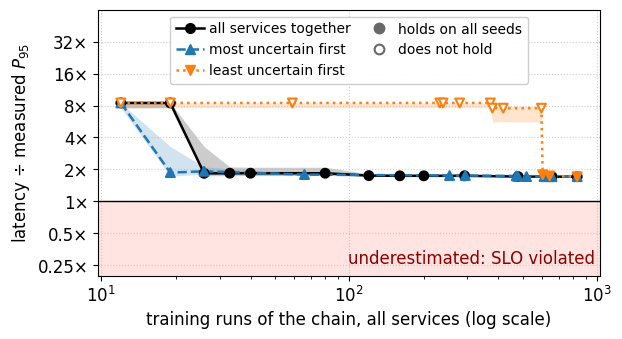

B.2 uncertainty of every service model, real data: denoiser → detector → faces → compressor, 107 held-out configurations, 3 seeds


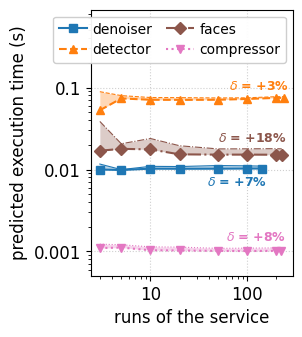

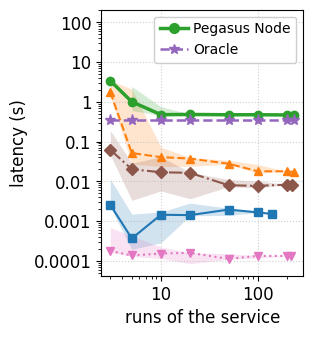

B.2 evidence per service, real data: denoiser → detector → faces → compressor, all services together, 107 held-out configurations, 3 seeds


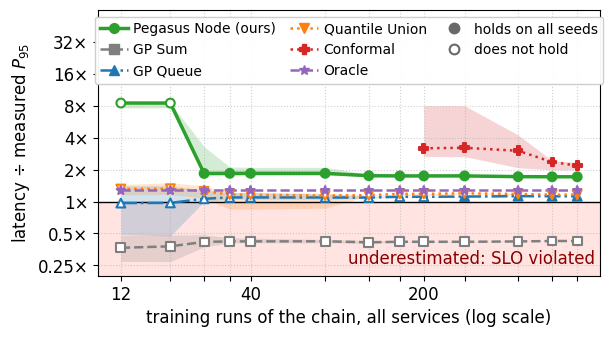

In [4]:
# B.2: coverage and tightness per training state; the ground truth is the same at every state
from pegasus.evaluation import uncertainty_figure

training_unit = "training runs" if data_source == "real" else "training configurations"
steps = list(range(n_steps))
per_step = lambda schedule: {(k, s): evidence[(schedule, s)][k][1] for k in steps for s in seeds}   # (step, seed) -> name -> (group, latency)
step_truth = {(k, s): evidence_truth[s] for k in steps for s in seeds}
runs_of = lambda schedule: np.array([[[evidence[(schedule, s)][k][0][node] for node in evidence_path] for s in seeds] for k in steps])   # (steps, seeds, services)
# total runs of the chain at every step, the median over the seeds (the same under every seed for ALL_TOGETHER)
evidence_totals = {schedule: np.median(runs_of(schedule).sum(axis=2), axis=1) for schedule in SCHEDULES}
schedule_statistics = {schedule: sweep_statistics(per_step(schedule), step_truth, steps, seeds, confidence)[PROPOSED] for schedule in SCHEDULES}
schedule_figure(evidence_totals, schedule_statistics,
                f"B.2 evidence per service, {data_source} data: {' → '.join(evidence_path)}, Pegasus Node under every schedule, "
                f"{len(evidence_truth[seeds[0]][0])} held-out configurations, {len(seeds)} seeds", p_label, name=f"b2_evidence_{data_source}_schedules")
# the Oracle uses no training data, so it is the same at every step; taken from the first step of every seed
oracle_bound = {s: float(np.median(evidence[(ALL_TOGETHER, s)][0][1]["Oracle"][1])) for s in seeds if "Oracle" in evidence[(ALL_TOGETHER, s)][0][1]}
uncertainty_figure(uncertainty, chain_bound, chain_pegasus, evidence_path,
                   f"B.2 uncertainty of every service model, {data_source} data: {' → '.join(evidence_path)}, "
                   f"{len(evidence_truth[seeds[0]][0])} held-out configurations, {len(seeds)} seeds", name=f"b2_evidence_{data_source}_uncertainty",
                   oracle=oracle_bound or None)

# every method under ALL_TOGETHER, whose totals are the same under every seed; a tick only where all services have the same number of runs
together = {(evidence_totals[ALL_TOGETHER][k], s): evidence[(ALL_TOGETHER, s)][k][1] for k in steps for s in seeds}
together_truth = {(evidence_totals[ALL_TOGETHER][k], s): evidence_truth[s] for k in steps for s in seeds}
together_totals = list(evidence_totals[ALL_TOGETHER])
evidence_statistics = sweep_statistics(together, together_truth, together_totals, seeds, confidence)   # name -> coverage, tightness, holds, computed
equal = runs_of(ALL_TOGETHER)[:, 0, :]
tightness_sweep_figure(together_totals, evidence_statistics, f"{training_unit} of the chain, all services (log scale)",
                       f"B.2 evidence per service, {data_source} data: {' → '.join(evidence_path)}, all services together, "
                       f"{len(evidence_truth[seeds[0]][0])} held-out configurations, {len(seeds)} seeds", p_label,
                       tick_labels=[f"{total:g}" if (row == row[0]).all() else "" for total, row in zip(together_totals, equal)],
                       name=f"b2_evidence_{data_source}_tightness")

In [5]:
total_label = lambda total: f"{total:g} {training_unit}"
# median over the seeds of the tightness of Pegasus Node at every step; a seed without a finite tightness counts as infinitely loose
typical = lambda schedule: np.median(np.nan_to_num(schedule_statistics[schedule]["tightness"], nan=np.inf), axis=1)
usable = lambda schedule: schedule_statistics[schedule]["holds"] & np.isfinite(typical(schedule))   # per step: holds with a finite bound


def schedule_text(schedule):
    ok, totals, tight = usable(schedule), evidence_totals[schedule], typical(schedule)
    if not ok.any():
        return f"*{schedule}*: no valid finite bound at any step"
    first = int(np.argmax(ok))
    best = int(np.argmin(np.where(ok, tight, np.inf)))
    stays = "and at every later step" if ok[first:].all() else "but not at every later step"
    return (f"*{schedule}*: valid and finite from {total_label(totals[first])} on ({tight[first]:.2f}×) {stays}; tightest "
            f"{tight[best]:.2f}× at {total_label(totals[best])}; {tight[-1]:.2f}× with all runs")


# per service and level of uncertainty_levels, the median over the seeds of the margin of the mean (column 1), the cost in s (column 2),
# the predicted mean in s (column 3) and the node bound with it in s (column 4)
service_runs = lambda service: uncertainty[seeds[0]][service][:, 0].astype(int)
uncertainty_median = lambda service, column: np.median([uncertainty[s][service][:, column] for s in seeds], axis=0)


seconds_text = lambda value: f"{value:.3g} s" if value >= 1 else f"{value * 1e3:.3g} ms"   # the times at a service span from below 1 ms to seconds
# the cost of the uncertainty of a service over the end-to-end bound of the chain with all runs, per seed, then the median over the seeds
share = lambda service: np.median([uncertainty[s][service][:, 2] / chain_bound[s] for s in seeds], axis=0)


def uncertainty_text(service):
    runs, margin, cost = service_runs(service), uncertainty_median(service, 1), uncertainty_median(service, 2)
    mean, bound = uncertainty_median(service, 3), uncertainty_median(service, 4)
    return (f"{service} (mean execution time {seconds_text(mean[-1])} and node bound {seconds_text(bound[-1])} with all {runs[-1]} runs): "
            f"margin {margin[0]:.2f} and cost {seconds_text(cost[0])} ({share(service)[0]:.2g} of the chain bound) with {runs[0]} runs, "
            f"{margin[-1]:.2f} and {seconds_text(cost[-1])} ({share(service)[-1]:.2g}) with all")


most_uncertain = max(evidence_path, key=lambda service: uncertainty_median(service, 1)[0])   # largest margin with the fewest runs
most_costly = max(evidence_path, key=lambda service: share(service)[0])                      # largest cost with the fewest runs
# per level of the chain (column 0 the runs per service): the median over the seeds of the bound of Pegasus Node (column 1)
chain_median = lambda column: np.median([chain_pegasus[s][:, column] for s in seeds], axis=0)


# a model is overconfident with few runs where its margin at some smaller number of runs is less than half the margin with all runs
overconfident = {service: service_runs(service)[int(np.argmin(uncertainty_median(service, 1)))] for service in evidence_path
                 if uncertainty_median(service, 1).min() < 0.5 * uncertainty_median(service, 1)[-1]}
first_moves = [evidence[(MOST_UNCERTAIN, s)][0][3] for s in seeds]   # the service that the rule moves up first, under every seed
display(Markdown(
    f"**What this shows** ({data_source} data, {' → '.join(evidence_path)}, ε = {alpha:g}, {len(seeds)} seeds; training runs counted "
    f"for the whole chain).\n"
    "- **Pegasus Node under every schedule** (median over the seeds): " + "; ".join(schedule_text(schedule) for schedule in SCHEDULES) + ".\n"
    f"- **Which service the rule feeds first.** Under *{MOST_UNCERTAIN}* the first service to get more runs is "
    + ", ".join(f"{service} (seed {s})" for service, s in zip(first_moves, seeds)) + ".\n"
    f"- **Uncertainty per service** (median over the seeds; the chain bound is that with the predicted means and all runs, "
    f"{seconds_text(np.median(list(chain_bound.values())))}): " + "; ".join(uncertainty_text(service) for service in evidence_path) + ". "
    + (f"With the fewest runs, {most_uncertain} is the most uncertain relative to its execution time, but {most_costly} costs the chain "
       f"the most: {share(most_costly)[0]:.2g} of the chain bound against {share(most_uncertain)[0]:.2g} for {most_uncertain}. "
       if most_uncertain != most_costly else f"With the fewest runs, {most_costly} is both the most uncertain and the most costly. ")
    + f"The chain bound of Pegasus Node is {seconds_text(chain_median(1)[0])} with {int(chain_median(0)[0])} runs per service and "
      f"{seconds_text(chain_median(1)[-1])} with all runs"
    + (f"; the Oracle is at {seconds_text(np.median(list(oracle_bound.values())))}" if oracle_bound else "") + ". "
    + (("Overconfident with few runs (smallest margin less than half the margin with all runs): "
        + ", ".join(f"{service} (smallest margin with {n} runs)" for service, n in overconfident.items())
        + ": with those few runs the model claims to know its mean better than it does with all runs, so the margin there "
          "understates the uncertainty.") if overconfident else
       "No model is markedly more confident with few runs than with all of them.") + "\n\n"
    f"*Every method under {ALL_TOGETHER}.*\n"
    + sweep_conclusion(together_totals, evidence_statistics, sweep_competitors, total_label)
))

**What this shows** (real data, denoiser → detector → faces → compressor, ε = 0.05, 3 seeds; training runs counted for the whole chain).
- **Pegasus Node under every schedule** (median over the seeds): *all services together*: valid and finite from 26 training runs on (1.84×) and at every later step; tightest 1.71× at 658 training runs; 1.71× with all runs; *most uncertain first*: valid and finite from 19 training runs on (1.87×) and at every later step; tightest 1.71× at 658 training runs; 1.71× with all runs; *least uncertain first*: valid and finite from 603 training runs on (1.78×) and at every later step; tightest 1.71× at 831 training runs; 1.71× with all runs.
- **Which service the rule feeds first.** Under *most uncertain first* the first service to get more runs is detector (seed 0), detector (seed 1), detector (seed 2).
- **Uncertainty per service** (median over the seeds; the chain bound is that with the predicted means and all runs, 409 ms): denoiser (mean execution time 10.3 ms and node bound 20.6 ms with all 142 runs): margin 0.17 and cost 2.55 ms (0.0062 of the chain bound) with 3 runs, 0.07 and 1.5 ms (0.0037) with all; detector (mean execution time 74.9 ms and node bound 269 ms with all 238 runs): margin 0.69 and cost 1.75 s (4.3 of the chain bound) with 3 runs, 0.03 and 17.2 ms (0.042) with all; faces (mean execution time 15.1 ms and node bound 35.1 ms with all 228 runs): margin 1.28 and cost 61.9 ms (0.15 of the chain bound) with 3 runs, 0.18 and 8.06 ms (0.02) with all; compressor (mean execution time 1.02 ms and node bound 1.66 ms with all 223 runs): margin 0.12 and cost 0.177 ms (0.00043 of the chain bound) with 3 runs, 0.08 and 0.131 ms (0.00032) with all. With the fewest runs, faces is the most uncertain relative to its execution time, but detector costs the chain the most: 4.3 of the chain bound against 0.15 for faces. The chain bound of Pegasus Node is 3.39 s with 3 runs per service and 467 ms with all runs; the Oracle is at 353 ms. Overconfident with few runs (smallest margin less than half the margin with all runs): denoiser (smallest margin with 5 runs): with those few runs the model claims to know its mean better than it does with all runs, so the margin there understates the uncertainty.

*Every method under all services together.*
- **Validity.** Methods that hold in every setting in which they are computed, i.e. reach the confidence level under every seed: Conformal. Methods that do not hold, and where: Pegasus Node (ours) at 12 training runs, 19 training runs; GP Sum at every setting; GP Queue at 12 training runs, 19 training runs, 26 training runs, 33 training runs, 40 training runs, 80 training runs, 120 training runs, 160 training runs, 200 training runs; Quantile Union at 12 training runs, 19 training runs, 26 training runs, 33 training runs, 40 training runs, 80 training runs, 120 training runs, 160 training runs, 200 training runs, 292 training runs. Conformal is not computed at 12 training runs, 19 training runs, 26 training runs, 33 training runs, 40 training runs, 80 training runs, 120 training runs, 160 training runs.
- **Tightness among the methods that hold** (median over the seeds): Conformal from 3.17× at 200 training runs to 2.18× at 831 training runs.